In [131]:
##Import librarires
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

##import performance metrices (as it is regression problem statement)
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error,root_mean_squared_error

#import regression ML models
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge,Lasso,ElasticNet
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor,AdaBoostRegressor
from xgboost import XGBRegressor



In [109]:
df=pd.read_csv("data/stud.csv")

In [110]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [111]:
###independent and dependent features
x=df.drop(columns='math score')
y=df['math score']

In [112]:
x.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,74
1,female,group C,some college,standard,completed,90,88
2,female,group B,master's degree,standard,none,95,93
3,male,group A,associate's degree,free/reduced,none,57,44
4,male,group C,some college,standard,none,78,75


In [113]:
y.head()

0    72
1    69
2    90
3    47
4    76
Name: math score, dtype: int64

In [114]:
#print categories of categorical columns
print(df['gender'].unique())
print(df['lunch'].unique())
print(df['race/ethnicity'].unique())
print(df['parental level of education'].unique())
print(df['test preparation course'].unique())

<StringArray>
['female', 'male']
Length: 2, dtype: str
<StringArray>
['standard', 'free/reduced']
Length: 2, dtype: str
<StringArray>
['group B', 'group C', 'group A', 'group D', 'group E']
Length: 5, dtype: str
<StringArray>
[ 'bachelor's degree',       'some college',    'master's degree',
 'associate's degree',        'high school',   'some high school']
Length: 6, dtype: str
<StringArray>
['none', 'completed']
Length: 2, dtype: str


In [115]:
##create column transformers
from sklearn.preprocessing import StandardScaler #numerical transformer
from sklearn.preprocessing import OneHotEncoder #categorical transformer
#
from sklearn.compose import ColumnTransformer 

##extracting features for transformation
cat_feature=x.select_dtypes(include='str').columns
num_features=x.select_dtypes(exclude='str').columns

cat_transformer=OneHotEncoder(drop='first')
num_transformer=StandardScaler()

preprocessor=ColumnTransformer([
    ('Standard Scaler',num_transformer,num_features),
    ('OneHot Encoder',cat_transformer,cat_feature)
])

In [116]:
##converting all the values 0 centered using transformers
x=preprocessor.fit_transform(x)

In [117]:
##seperate the dataset into training_data & testing_data
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.20,random_state=42)

In [118]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(800, 14)
(200, 14)
(800,)
(200,)


Created a Evaluation Function for Evalauting models:

In [119]:
def evaluate_matrices(true,predicted):
    
    r2_Square=r2_score(true,predicted)
    MSE=mean_squared_error(true,predicted)
    MAE=mean_absolute_error(true,predicted)
    RMSE=root_mean_squared_error(true,predicted)
    return r2_Square,MSE,MAE,RMSE


In [120]:
##Creating key,Value pairs of models
models={
    'LinearRegression':LinearRegression(),
    'Ridge':Ridge(),
    'Lasso':Lasso(),
    'ElasticNet':ElasticNet(),
    'SVR':SVR(),
    'Decision Tree':DecisionTreeRegressor(),
    'K-neighbors':KNeighborsRegressor(),
    'Random Forest':RandomForestRegressor(),
    'Gradient Boost':GradientBoostingRegressor(),
    'AdaBoostRegressor':AdaBoostRegressor(),
    'xgBoost':XGBRegressor()
    }

model_list=[]
r2_list=[]

for i in range(len(list(models))):
    model=list(models.values())[i] #loading models using iteration
    model.fit(x_train,y_train) #Model fitting over training data

    ##making prediction
    y_train_predict=model.predict(x_train)
    y_test_predict=model.predict(x_test)

    #evaluate matrices  & calling the evaluate matrices function
    model_train_r2,model_train_mse,model_train_RMSE,model_train_MAE=evaluate_matrices(y_train,y_train_predict)
    model_test_r2,model_test_mse,model_test_RMSE,model_test_MAE=evaluate_matrices(y_test,y_test_predict)

    print(list(models.keys())[i])
    model_list.append(list(models.keys())[i])

    print('--------Training set performance----------')

    print("-Mean Squared Error: {:.4f}".format(model_train_mse))
    print("-Mean Absolute Error: {:.4f}".format(model_train_MAE))
    print("-Root mean squared Error: {:.4f}".format(model_train_RMSE))
    print("-R2 Score: {:.4f}".format(model_train_r2))

    print('------Testing set performance--------------')

    print("-Mean Squared Error: {:.4f}".format(model_test_mse))
    print("-Mean Absolute Error: {:.4f}".format(model_test_MAE))
    print("-Root mean squared Error: {:.4f}".format(model_test_RMSE))
    print("-R2 Score: {:.4f}".format(model_test_r2))
    r2_list.append(model_test_r2)

    print("="*40)
    print("\n")

LinearRegression
--------Training set performance----------
-Mean Squared Error: 28.3349
-Mean Absolute Error: 5.3231
-Root mean squared Error: 4.2667
-R2 Score: 0.8743
------Testing set performance--------------
-Mean Squared Error: 29.0952
-Mean Absolute Error: 5.3940
-Root mean squared Error: 4.2148
-R2 Score: 0.8804


Ridge
--------Training set performance----------
-Mean Squared Error: 28.3397
-Mean Absolute Error: 5.3235
-Root mean squared Error: 4.2650
-R2 Score: 0.8743
------Testing set performance--------------
-Mean Squared Error: 29.0908
-Mean Absolute Error: 5.3936
-Root mean squared Error: 4.2125
-R2 Score: 0.8805


Lasso
--------Training set performance----------
-Mean Squared Error: 43.4783
-Mean Absolute Error: 6.5938
-Root mean squared Error: 5.2063
-R2 Score: 0.8071
------Testing set performance--------------
-Mean Squared Error: 42.5063
-Mean Absolute Error: 6.5197
-Root mean squared Error: 5.1579
-R2 Score: 0.8253


ElasticNet
--------Training set performance-------

In [121]:
##Hyperparameter Tunning
from sklearn.model_selection import RandomizedSearchCV
rf_params={
      'n_estimators':[100,200,500,1000],
      'max_depth':[2,5,6,7,10],
      'min_samples_split':[2,3,7,3,4,2],
      'max_features':['sqrt','log2'],
      'criterion':['squared_error','friedman_mse','poisson','absolute_error']
}

random_cv=[
    ('Random Forest',RandomForestRegressor(),rf_params)
]

model_params={}

for name,model,param in random_cv:
    cvmodel=RandomizedSearchCV(param_distributions=param,estimator=model,n_iter=100,refit=True,verbose=3,cv=5)
    cvmodel.fit(x_train,y_train)
    model_params[name]=cvmodel.best_params_


for model_name in model_params:
    print(f'-----Best Parameters for {model_name}-----------')
    print(model_params[model_name])


Fitting 5 folds for each of 100 candidates, totalling 500 fits
[CV 1/5] END criterion=friedman_mse, max_depth=5, max_features=sqrt, min_samples_split=2, n_estimators=500;, score=nan total time=   0.0s
[CV 2/5] END criterion=friedman_mse, max_depth=5, max_features=sqrt, min_samples_split=2, n_estimators=500;, score=nan total time=   0.0s
[CV 3/5] END criterion=friedman_mse, max_depth=5, max_features=sqrt, min_samples_split=2, n_estimators=500;, score=nan total time=   0.0s
[CV 4/5] END criterion=friedman_mse, max_depth=5, max_features=sqrt, min_samples_split=2, n_estimators=500;, score=nan total time=   0.0s
[CV 5/5] END criterion=friedman_mse, max_depth=5, max_features=sqrt, min_samples_split=2, n_estimators=500;, score=nan total time=   0.0s
[CV 1/5] END criterion=squared_error, max_depth=10, max_features=sqrt, min_samples_split=4, n_estimators=500;, score=0.835 total time=   0.3s
[CV 2/5] END criterion=squared_error, max_depth=10, max_features=sqrt, min_samples_split=4, n_estimators=

In [122]:
##model Random forest Training after hyperparameter tunning
##Creating key,Value pairs of models
models={
    'Random Forest':RandomForestRegressor(n_estimators=200,min_samples_split=3,max_features='sqrt',max_depth=10,criterion='squared_error')
    }

model_list=[]
r2_list=[]

for i in range(len(list(models))):
    model=list(models.values())[i] #loading models using iteration
    model.fit(x_train,y_train) #Model fitting over training data

    ##making prediction
    y_train_predict=model.predict(x_train)
    y_test_predict=model.predict(x_test)

    #evaluate matrices  & calling the evaluate matrices function
    model_train_r2,model_train_mse,model_train_RMSE,model_train_MAE=evaluate_matrices(y_train,y_train_predict)
    model_test_r2,model_test_mse,model_test_RMSE,model_test_MAE=evaluate_matrices(y_test,y_test_predict)

    print(list(models.keys())[i])
    model_list.append(list(models.keys())[i])

    print('--------Training set performance----------')

    print("-Mean Squared Error: {:.4f}".format(model_train_mse))
    print("-Mean Absolute Error: {:.4f}".format(model_train_MAE))
    print("-Root mean squared Error: {:.4f}".format(model_train_RMSE))
    print("-R2 Score: {:.4f}".format(model_train_r2))

    print('------Testing set performance--------------')

    print("-Mean Squared Error: {:.4f}".format(model_test_mse))
    print("-Mean Absolute Error: {:.4f}".format(model_test_MAE))
    print("-Root mean squared Error: {:.4f}".format(model_test_RMSE))
    print("-R2 Score: {:.4f}".format(model_test_r2))
    r2_list.append(model_test_r2)

    print("="*40)
    print("\n")

Random Forest
--------Training set performance----------
-Mean Squared Error: 14.1287
-Mean Absolute Error: 3.7588
-Root mean squared Error: 2.9978
-R2 Score: 0.9373
------Testing set performance--------------
-Mean Squared Error: 45.2017
-Mean Absolute Error: 6.7232
-Root mean squared Error: 5.1186
-R2 Score: 0.8142




In [123]:
pd.DataFrame(list(zip(model_list,r2_list)), columns=['Model_Name', 'R2_Score']).sort_values(by=["R2_Score"],ascending=False)

,Model_Name,R2_Score
0,Random Forest,0.814244


In [124]:
pd.DataFrame(list(zip(model_list,r2_list)), columns=['Model_Name', 'R2_Score']).sort_values(by=["R2_Score"],ascending=False)

,Model_Name,R2_Score
0,Random Forest,0.814244


Observation:
1. it is observed that model Linear regression and Ridge is performing over this dataset with excellent accuracy 0.88

In [125]:
##linear regression
model=LinearRegression()
model.fit(x_train,y_train)
y_lin_test=model.predict(x_test)
r2_square=r2_score(y_test,y_lin_test)
print("Accuracy of linear regression model is : {:.2f}".format(r2_square))

Accuracy of linear regression model is : 0.88


Text(0, 0.5, 'Predicted Values')

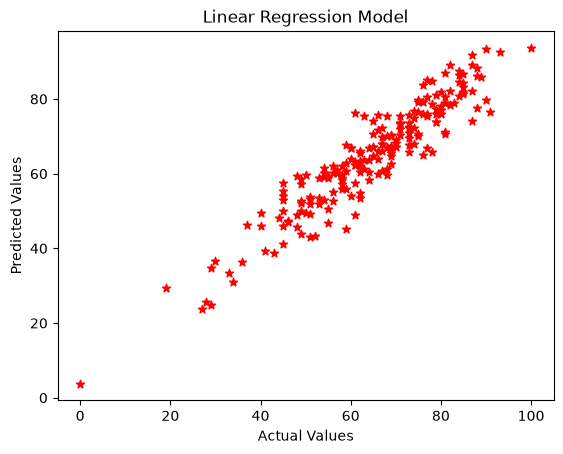

In [126]:
plt.scatter(y_test,y_lin_test,marker='*',color='red')
plt.title("Linear Regression Model")
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")

<Axes: xlabel='math score'>

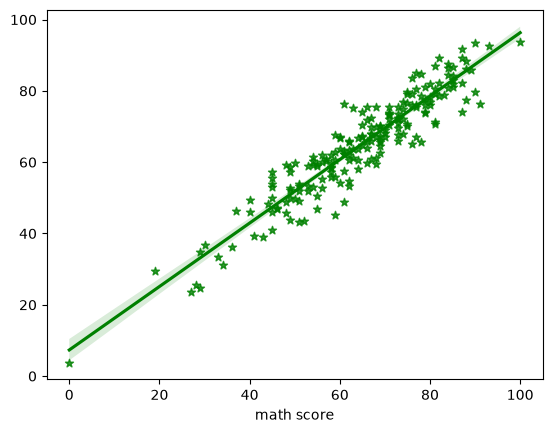

In [130]:
##plot the regression line
sns.regplot(x=y_test,y=y_lin_test,color='green',marker='*')


##Best fit line for predicted math score

In [128]:
#difference between actual values and predicted values
pd.DataFrame({
    'Actual Values':y_test,
    'Predicted Values':y_lin_test,
    'Difference':y_test-y_lin_test
    })

,Actual Values,Predicted Values,Difference
521,91,76.387970,14.612030
737,53,58.885970,-5.885970
740,80,76.990265,3.009735
660,74,76.851804,-2.851804
411,84,87.627378,-3.627378
...,...,...,...
408,52,43.409149,8.590851
332,62,62.152214,-0.152214
208,74,67.888395,6.111605
613,65,67.022287,-2.022287
